# Reduced-Dimension Representations

Investigate linear and neural representations of numeric donor data, using the original estimators and settings.

**References:** [scikit-learn decomposition](https://scikit-learn.org/stable/modules/decomposition.html), [SciPy](https://docs.scipy.org/doc/scipy/), [Keras](https://keras.io/).

In [1]:
# Environment setup: install the packages used by this notebook in the selected kernel.
!pip install feature_engine
!pip install mlxtend

In [2]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
import pandas as pd, numpy as np, seaborn as sns
import sklearn, scipy, torch
import matplotlib.pyplot as plt
import plotly.express as px
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from sklearn.decomposition import TruncatedSVD, PCA

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from sklearn.model_selection import cross_val_predict, cross_validate, cross_val_score
from sklearn.model_selection import train_test_split, StratifiedKFold

import warnings
warnings.filterwarnings('ignore')

import sys
# Local utils.py is provided alongside this notebook.
import utils as ad

In [3]:
# Load the project dataset from its local data directory and inspect its schema.
charity = pd.read_csv('data/donor_numeric_inputs.csv', sep=';')
charity.info()

<class 'pandas.DataFrame'>
RangeIndex: 2398 entries, 0 to 2397
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   f09_spend_before_campaign   2398 non-null   float64
 1   f10_visits_before_campaign  2398 non-null   float64
 2   f12_overall_visit_count     2398 non-null   float64
 3   f13_overall_spend_amount    2398 non-null   float64
 4   f01_mosaic_segment          2398 non-null   float64
 5   f08_mosaic_band             2398 non-null   float64
 6   f14_birth_year              2398 non-null   float64
 7   f02_age_years               2398 non-null   float64
 8   f11_campaign_response       2398 non-null   str    
dtypes: float64(8), str(1)
memory usage: 168.7 KB


In [4]:
# Inspect the current dataframe to confirm its structure and values.
charity.describe()

,f09_spend_before_campaign,f10_visits_before_campaign,f12_overall_visit_count,f13_overall_spend_amount,f01_mosaic_segment,f08_mosaic_band,f14_birth_year,f02_age_years
count,2398.000000,2398.000000,2398.000000,2398.000000,2398.000000,2398.000000,2398.000000,2398.000000
mean,89.352794,4.378649,5.221435,104.657214,18.804837,4.601334,1950.366555,43.633445
std,95.663303,6.201329,7.542659,122.778809,14.337616,3.100384,13.444036,13.444036
min,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1902.000000,19.000000
25%,59.000000,1.000000,2.000000,61.000000,7.000000,2.000000,1942.000000,33.000000
50%,72.000000,3.000000,3.000000,78.000000,12.000000,3.000000,1952.000000,42.000000
75%,88.000000,5.000000,6.000000,98.000000,31.000000,7.000000,1961.000000,52.000000
max,1303.000000,116.000000,131.000000,1787.000000,51.000000,12.000000,1975.000000,92.000000


In [5]:
# Separate predictors from the target using the original column-selection rule.
charity[charity.columns.difference(['f11_campaign_response'])].corr()

,f01_mosaic_segment,f02_age_years,f08_mosaic_band,f09_spend_before_campaign,f10_visits_before_campaign,f12_overall_visit_count,f13_overall_spend_amount,f14_birth_year
f01_mosaic_segment,1.000000,-0.110326,0.993963,-0.009259,0.004693,0.011059,0.006220,0.110326
f02_age_years,-0.110326,1.000000,-0.106709,0.035100,0.082770,0.093813,0.056893,-1.000000
f08_mosaic_band,0.993963,-0.106709,1.000000,-0.007386,0.006900,0.014659,0.010261,0.106709
f09_spend_before_campaign,-0.009259,0.035100,-0.007386,1.000000,0.829242,0.817275,0.930795,-0.035100
f10_visits_before_campaign,0.004693,0.082770,0.006900,0.829242,1.000000,0.976092,0.797224,-0.082770
f12_overall_visit_count,0.011059,0.093813,0.014659,0.817275,0.976092,1.000000,0.841645,-0.093813
f13_overall_spend_amount,0.006220,0.056893,0.010261,0.930795,0.797224,0.841645,1.000000,-0.056893
f14_birth_year,0.110326,-1.000000,0.106709,-0.035100,-0.082770,-0.093813,-0.056893,1.000000


In [6]:
# Create the predefined training and validation partitions without changing split parameters.
# Separate reg. attr. from class label attr.
X = charity[charity.columns.difference(['f11_campaign_response'])]
y = charity['f11_campaign_response']
# Split data.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=43)

## 1. Establish a full-feature baseline

Begin with the original predictor matrix before reducing its dimensionality.

In [7]:
# Evaluate the current estimator using the configured cross-validation strategy.
clf = SVC(random_state=43)
# Crossvalidate on the train portion using the custom function.
ad.report_classification_cv(X_train, y_train, clf)
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))

Mean Accuracy is 73.77 +/- 1.04
Mean Precision is 81.13 +/- 3.31
Mean Recall is 58.22 +/- 1.39
Mean F-score is 56.46 +/- 2.11
               precision    recall  f1-score   support

Non-responder       0.72      0.99      0.83       323
    Responder       0.92      0.21      0.34       157

     accuracy                           0.74       480
    macro avg       0.82      0.60      0.59       480
 weighted avg       0.78      0.74      0.67       480



## 2. Truncated singular-value decomposition

Examine singular values and low-rank representations. Truncated SVD projects the data onto selected components without automatically centering features.

In [8]:
# Create the reduced-dimensional representation using the original component settings.
# Sklearn truncated svd with all components.
svd = TruncatedSVD(n_components=len(X.columns), random_state=43)
svd.fit(X)
s = svd.singular_values_
print([format("%.3f" % singular_value) for singular_value in s])
# Also print the proportions of explained variance.
print([format("%.3f" % expl_var) for expl_var in svd.explained_variance_ratio_])

['95778.233', '7490.127', '1374.467', '735.562', '649.938', '254.329', '36.485', '16.239']
['0.011', '0.940', '0.032', '0.009', '0.007', '0.001', '0.000', '0.000']


In [9]:
# Inspect the current dataframe to confirm its structure and values.
# Looking at the result above, we can easily use only 5 out of the 8 components.
svd = TruncatedSVD(n_components=5, algorithm='arpack', random_state=43)
X_svd = svd.fit_transform(X_train)
# Store the components into a dataframe.
X_svd = pd.DataFrame(X_svd, columns=list(svd.get_feature_names_out()))
X_svd.head()

,truncatedsvd0,truncatedsvd1,truncatedsvd2,truncatedsvd3,truncatedsvd4
0,1939.891446,3.721381,3.727072,-18.304400,9.149845
1,1933.881048,-58.462116,2.217797,7.799178,27.057005
2,1972.829936,-19.218352,8.503842,19.085294,-10.337647
3,1948.599282,-27.136371,6.830773,-5.612530,3.547278
4,1936.254763,-6.157846,6.747698,-20.758818,11.602002


In [10]:
# Continue the analysis using the original transformation and model parameters.
# Svd loadings are computed as: svd.components_.T X svd.singular_values_.
svd_loadings = svd.components_.T * svd.singular_values_
# Put them into a dataframe: the rows are the original attributes and columns are the new components.
svd_loadings = pd.DataFrame(svd_loadings, index=X.columns,
                  columns=[f'SVD{i}' for i in range(len(svd.components_))])
svd_loadings

,SVD0,SVD1,SVD2,SVD3,SVD4
f01_mosaic_segment,833.928551,-10.113166,-18.108801,557.154601,294.387894
f02_age_years,1904.451229,25.974740,-38.175043,-340.062864,504.221928
f08_mosaic_band,203.890324,-1.759994,-5.078760,119.287985,63.864396
f09_spend_before_campaign,3920.911178,4142.236938,872.956490,-0.032330,15.179564
f10_visits_before_campaign,193.654691,226.214696,25.743718,-2.176413,14.076542
f12_overall_visit_count,229.687502,278.367898,-13.916604,-3.612047,16.923468
f13_overall_spend_amount,4548.251434,5247.019133,-689.580595,3.261004,-16.666737
f14_birth_year,85419.557008,-471.256549,-2.333756,1.700200,-14.154981


<Axes: >

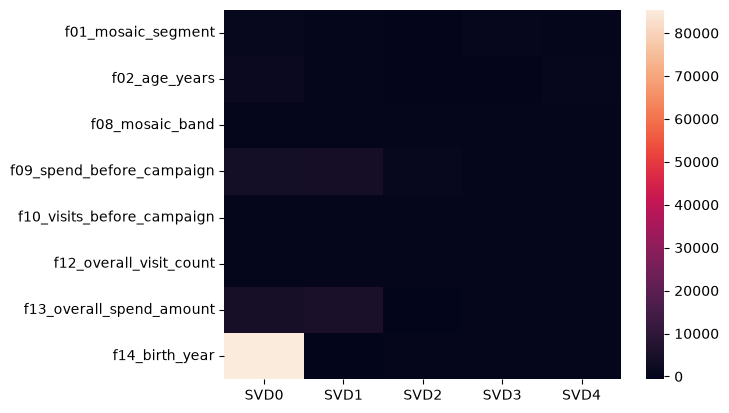

In [11]:
# Visualize the current measurements or fitted results for interpretation.
sns.heatmap(svd_loadings)

In [12]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Fit the estimator using the designated training observations.
X_test_svd = svd.transform(X_test)
X_test_svd = pd.DataFrame(X_test_svd, columns=list(svd.get_feature_names_out()))
clf = SVC(random_state=43)
ad.report_classification_cv(X_svd, y_train, clf)
y_pred = clf.predict(X_test_svd)
print(classification_report(y_test, y_pred))

Mean Accuracy is 73.77 +/- 1.04
Mean Precision is 81.13 +/- 3.31
Mean Recall is 58.22 +/- 1.39
Mean F-score is 56.46 +/- 2.11
               precision    recall  f1-score   support

Non-responder       0.72      0.99      0.84       323
    Responder       0.92      0.22      0.36       157

     accuracy                           0.74       480
    macro avg       0.82      0.61      0.60       480
 weighted avg       0.79      0.74      0.68       480



## 3. Principal component analysis

Use PCA to project centered data along directions of high variance. Compare component contributions and the resulting representation with SVD.

In [13]:
# Create the reduced-dimensional representation using the original component settings.
# N_componetns=None by default, which means is equal to number of features.
pca = PCA(svd_solver='randomized', random_state=43)
pca.fit(X)
s = pca.singular_values_
print([format("%.3f" % singular_value) for singular_value in s])
# Also print the proportions of explained variance.
print([format("%.3f" % expl_var) for expl_var in pca.explained_variance_ratio_])

['7506.486', '1375.707', '935.942', '706.094', '254.430', '36.485', '16.239', '0.000']
['0.944', '0.032', '0.015', '0.008', '0.001', '0.000', '0.000', '0.000']


In [14]:
# Inspect the current dataframe to confirm its structure and values.
# Looking at the result above, we can easily use only 5 out of the 8 components.
pca = PCA(n_components=5, svd_solver='arpack', random_state=43)
X_pca = pca.fit_transform(X_train)
# Store the components into a dataframe.
X_pca = pd.DataFrame(X_pca, columns=list(pca.get_feature_names_out()))
X_pca.head()

,pca0,pca1,pca2,pca3,pca4
0,3.444202,2.326265,-25.400289,-6.234096,6.787470
1,-58.998430,0.799642,-21.919062,25.292847,-3.176861
2,-17.270662,10.065401,27.264406,5.899728,-4.078209
3,-26.771036,6.359088,-8.774071,-1.344007,-2.762362
4,-6.653412,5.082734,-30.127893,-6.181461,10.691168


In [15]:
# Continue the analysis using the original transformation and model parameters.
# Pca loadings are computed as: pca.components_.T * np.sqrt(pca.explained_variance_).
pca_loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
# Put them into a dataframe: the rows are the original attributes and columns are the new components.
pca_loadings = pd.DataFrame(pca_loadings, index=X.columns,
                  columns=[f'PCA{i}' for i in range(len(pca.components_))])
pca_loadings

,PCA0,PCA1,PCA2,PCA3,PCA4
f01_mosaic_segment,-0.123533,-0.290591,3.822365,13.894896,-0.068485
f02_age_years,0.737249,-1.449760,-13.392854,2.046742,-0.088980
f08_mosaic_band,-0.014319,-0.089866,0.809394,2.987206,-0.015085
f09_spend_before_campaign,95.070703,19.913034,-1.067641,0.301817,-0.201437
f10_visits_before_campaign,5.188050,0.576275,-0.272875,0.177425,3.393321
f12_overall_visit_count,6.382678,-0.331724,-0.300379,0.192998,3.974747
f13_overall_spend_amount,120.365939,-15.718052,1.039047,-0.266728,-0.196907
f14_birth_year,-0.737249,1.449760,13.392854,-2.046742,0.088980


<Axes: >

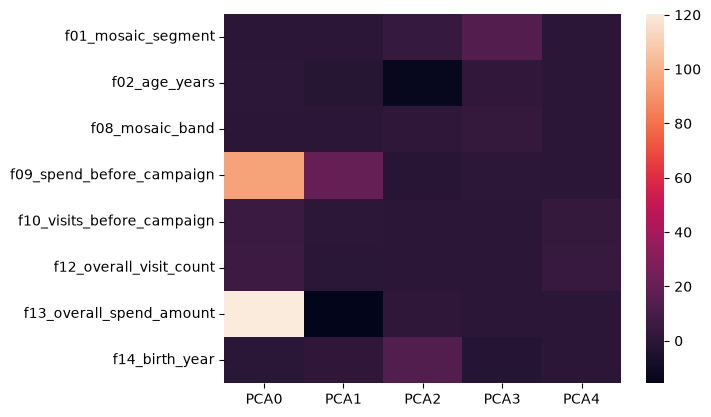

In [16]:
# Visualize the current measurements or fitted results for interpretation.
sns.heatmap(pca_loadings)

In [17]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Fit the estimator using the designated training observations.
X_pca_test = pca.transform(X_test)
X_pca_test = pd.DataFrame(X_pca_test, columns=list(pca.get_feature_names_out()))
clf = SVC(random_state=43)
ad.report_classification_cv(X_pca, y_train, clf)
y_pred = clf.predict(X_pca_test)
print(classification_report(y_test, y_pred))

Mean Accuracy is 90.98 +/- 1.02
Mean Precision is 93.27 +/- 1.16
Mean Recall is 85.95 +/- 1.39
Mean F-score is 88.56 +/- 1.34
               precision    recall  f1-score   support

Non-responder       0.90      1.00      0.95       323
    Responder       0.99      0.77      0.87       157

     accuracy                           0.92       480
    macro avg       0.95      0.88      0.91       480
 weighted avg       0.93      0.92      0.92       480



### Effect of scaling

Standardization can substantially change PCA and SVD directions when input measurements use different units.

In [18]:
# Fit the configured transformer and apply it to the selected observations.
# Scale regular attributes since ranges are quite different.
X_scaled = StandardScaler().fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

In [19]:
# Inspect the current dataframe to confirm its structure and values.
svd = TruncatedSVD(n_components=8, algorithm='randomized', random_state=43)
X_svd = svd.fit_transform(X_scaled)
# Store the components into a dataframe.
X_svd = pd.DataFrame(X_svd, columns=list(svd.get_feature_names_out()))
X_svd.head()

,truncatedsvd0,truncatedsvd1,truncatedsvd2,truncatedsvd3,truncatedsvd4,truncatedsvd5,truncatedsvd6,truncatedsvd7
0,-1.094056,3.192452,-0.364795,0.040938,0.029386,-0.010510,0.036313,-2.831863e-15
1,-1.170754,1.101383,-2.232954,-0.113244,0.002123,0.007136,-0.024831,-2.654019e-15
2,-0.492965,1.387995,-2.043773,0.377324,0.035077,-0.041332,-0.156232,-2.209930e-15
3,-0.815489,2.260362,-1.162638,0.087420,0.044392,-0.025461,0.177578,-2.431974e-15
4,-0.583262,1.416180,-1.864642,0.178550,0.046533,-0.030589,-0.007683,-2.698220e-15


In [20]:
# Inspect the current dataframe to confirm its structure and values.
pca = PCA(n_components=8, svd_solver='randomized', random_state=43)
X_pca = pca.fit_transform(X_scaled)
# Store the components into a dataframe.
X_pca = pd.DataFrame(X_pca, columns=list(pca.get_feature_names_out()))
X_pca.head()

,pca0,pca1,pca2,pca3,pca4,pca5,pca6,pca7
0,-1.094056,3.192452,0.364795,0.040938,0.029386,-0.010510,0.036313,-3.586334e-17
1,-1.170754,1.101383,2.232954,-0.113244,0.002123,0.007136,-0.024831,1.951331e-16
2,-0.492965,1.387995,2.043773,0.377324,0.035077,-0.041332,-0.156232,-1.376731e-16
3,-0.815489,2.260362,1.162638,0.087420,0.044392,-0.025461,0.177578,3.684436e-18
4,-0.583262,1.416180,1.864642,0.178550,0.046533,-0.030589,-0.007683,-6.256581e-18


In [21]:
# Continue the analysis using the original transformation and model parameters.
print("======= SVD Results ========")
print([format("%.3f" % sing_val) for sing_val in svd.singular_values_])
print([format("%.3f" % expl_var) for expl_var in svd.explained_variance_ratio_])
print("======= PCA Results ========")
print([format("%.3f" % sing_val) for sing_val in pca.singular_values_])
print([format("%.3f" % expl_var) for expl_var in pca.explained_variance_ratio_])

======= SVD Results ========
['93.155', '72.691', '65.164', '27.217', '14.014', '4.915', '3.794', '0.000']
['0.452', '0.275', '0.221', '0.039', '0.010', '0.001', '0.001', '0.000']
======= PCA Results ========
['93.155', '72.691', '65.164', '27.217', '14.014', '4.915', '3.794', '0.000']
['0.452', '0.275', '0.221', '0.039', '0.010', '0.001', '0.001', '0.000']


### Visualize component coordinates

Plot low-dimensional projections by the recorded campaign-response label to inspect apparent separation. Visual separation alone does not establish predictive validity.

Text(0.5, 1.0, "Fist 2 PCA components coloured by 'f11_campaign_response'")

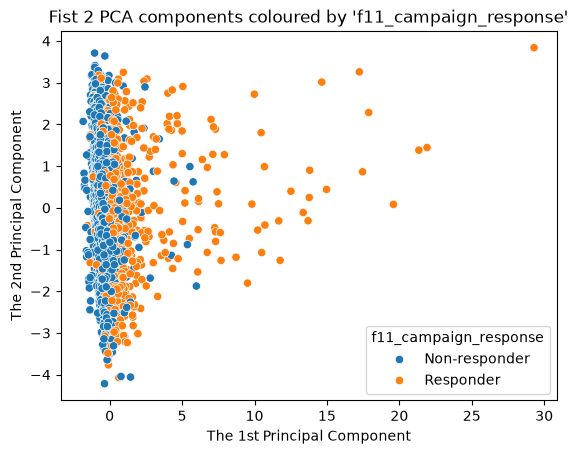

In [22]:
# Visualize the current measurements or fitted results for interpretation.
sns.scatterplot(x=X_pca.pca0, y=X_pca.pca1, hue=y)
plt.xlabel("The 1st Principal Component")
plt.ylabel("The 2nd Principal Component")
plt.title("Fist 2 PCA components coloured by 'f11_campaign_response'")

In [23]:
# Inspect or update the intermediate result produced by the preceding step.
# Optional comparison: review this configuration against the original baseline.
# The first 3 SVD components coloured by class; interpret the results.

### Select the number of components

Compare cumulative explained variance, scree plots and predictive scores. Retained variance and prediction quality answer different questions.

Text(0, 0.5, 'Accuracy')

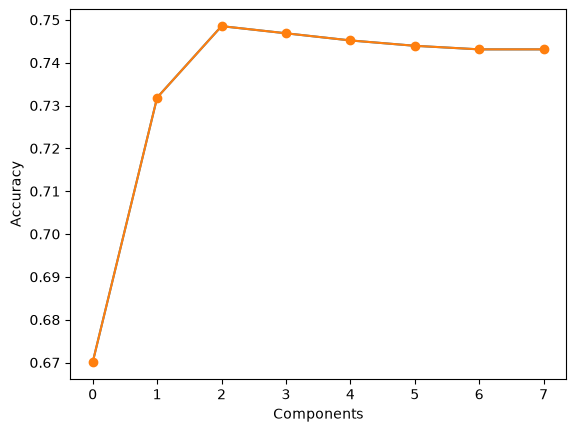

In [24]:
# Evaluate the current estimator using the configured cross-validation strategy.
# 1.1. use scree plot to plot f1-scores across various number of components.
accuracies = []
cumulative_variances = []
for n_comps in range(1, len(X.columns)+1):
  svd = TruncatedSVD(n_components=n_comps, random_state=43)
  X_svd = svd.fit_transform(X)
  f1 = cross_validate(clf, X_svd, y)
  accuracies.append(f1['test_score'].mean())
  cumulative_variances.append(np.sum(svd.explained_variance_ratio_))
ax = sns.lineplot(data=accuracies)
plt.plot(accuracies, marker='o')
plt.xlabel('Components')
plt.ylabel('Accuracy')

Text(0, 0.5, 'Cumulative Explained Variance')

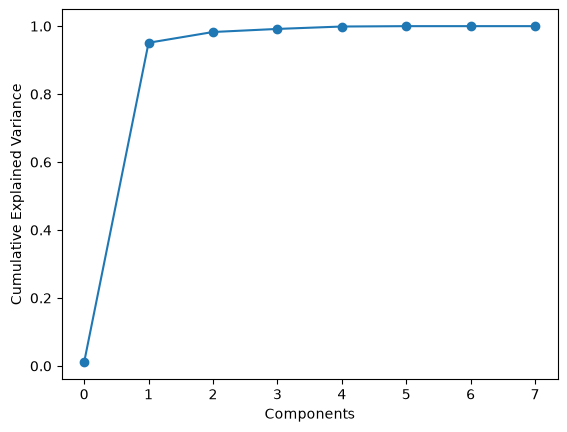

In [25]:
# Visualize the current measurements or fitted results for interpretation.
# 1.2. use scree plot to plot the explained variance captured by each component.
plt.plot(cumulative_variances, marker='o')
plt.xlabel('Components')
plt.ylabel('Cumulative Explained Variance')

In [26]:
# Inspect or update the intermediate result produced by the preceding step.
# Optional comparison: review this configuration against the original baseline.

### Avoid preprocessing leakage

Fit dimensionality reduction separately within each training fold when comparing predictive performance.

In [27]:
# Evaluate the current estimator using the configured cross-validation strategy.
prep_pipeline = Pipeline(steps=[
    ('svd', TruncatedSVD(n_components=5, random_state=43))
])
ad.evaluate_pipeline_cv(clf, prep_pipeline, X_train, y_train)

Mean Accuracy is 73.88 +/- 1.04
Mean Precision is 81.50 +/- 2.85
Mean Recall is 58.39 +/- 1.57
Mean F-score is 56.70 +/- 2.50


In [28]:
# Evaluate the current estimator using the configured cross-validation strategy.
prep_pipeline = Pipeline(steps=[
    ('svd', PCA(n_components=5, random_state=43))
])
ad.evaluate_pipeline_cv(clf, prep_pipeline, X_train, y_train)

Mean Accuracy is 90.88 +/- 1.77
Mean Precision is 93.40 +/- 1.48
Mean Recall is 85.69 +/- 2.74
Mean F-score is 88.35 +/- 2.48


## 4. Alternative implementations

The optional code compares other numerical library interfaces without changing the underlying data.

In [29]:
# Inspect or update the intermediate result produced by the preceding step.
# 1.1. numpy implementation of svd function.
# Which returns 3 things, but we are only interested in the vector.
# With singular values which are sorted in descending order.
U, s, V = np.linalg.svd(X_scaled)
# Print the singular values (with a prec.of 3 decimal digits).
print([format("%.3f" % singular_value) for singular_value in s])

['93.155', '72.691', '65.164', '27.217', '14.014', '4.915', '3.794', '0.000']


In [30]:
# Inspect or update the intermediate result produced by the preceding step.
# 1.2. scipy implementation of svd function is very similar to numpy.
# It returns 3 things, but we are only interested in the vector.
# With singular values which are sorted in descending order.
U1, s1, V1 = scipy.linalg.svd(X_scaled)
# Print the singular values (with a prec.of 3 decimal digits).
print([format("%.3f" % singular_value) for singular_value in s1])

['93.155', '72.691', '65.164', '27.217', '14.014', '4.915', '3.794', '0.000']


In [31]:
# Inspect or update the intermediate result produced by the preceding step.
# Optional comparison: review this configuration against the original baseline.
# SVD feature reduction and build a KNN model to compare to the results above.

# Optional comparison: review this configuration against the original baseline.
# Get the loadings and visualise them.

# Optional comparison: review this configuration against the original baseline.

## 5. Autoencoder representations

Train an encoder–decoder network to reconstruct the input features through a smaller latent space. Reconstruction loss is not the same as downstream classification performance.

In [32]:
# Inspect or update the intermediate result produced by the preceding step.
from tensorflow import keras
from tensorflow.keras import layers

I0000 00:00:1793875017.634853    9928 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793875018.749581    9928 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [33]:
# Continue the analysis using the original transformation and model parameters.
input_dim = X_train.shape[1]  # Number of original features.
encoding_dim = 7  # Number of new components.

autoencoder = keras.Sequential([
    # Encode the selected categorical fields for the estimator.
    layers.Input(shape=(input_dim,)),
    layers.Dense(16, activation='relu', kernel_regularizer='l2'),
    layers.Dense(10, activation='relu'),
    layers.Dense(encoding_dim, activation='relu'),

    # Decoder part (asymmetry is better).
    layers.Dense(12, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(input_dim, activation='linear')  # Activation could be sigmoid.
])

autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.summary()

E0000 00:00:1793875060.908952    9928 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           170 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │            77 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 12)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │           136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 831 (3.25 KB)

 Trainable params: 831 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 473971.9062 - val_loss: 470106.9375
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 466819.9688 - val_loss: 462024.2812
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 457235.1562 - val_loss: 450368.8125
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 443699.8750 - val_loss: 434176.3438
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 425490.5312 - val_loss: 413850.5938
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 403165.7188 - val_loss: 387002.9062
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 372067.1562 - val_loss: 349912.3125
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 330545.7188 - val_loss: 301779.9375
Epoch 9/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 277685.0938 - val_loss: 242151.5000
Epoch 10/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 213613.5000 - val_loss: 170711.2656
Epoch 11/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 137999.6719 - val_l

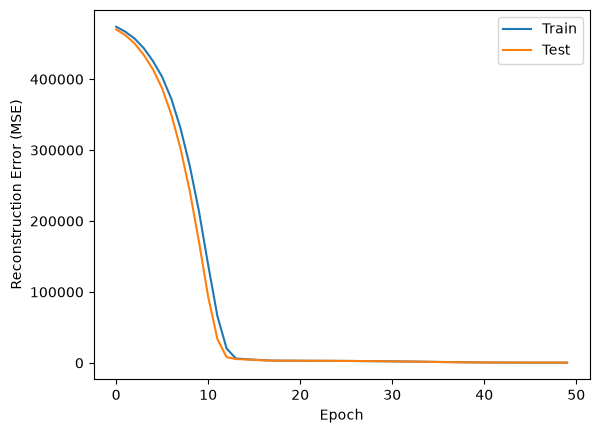

In [34]:
# Visualize the current measurements or fitted results for interpretation.
# Encode the selected categorical fields for the estimator.
history = autoencoder.fit(
    X_train, X_train,
    epochs=50,
    batch_size=256,
    shuffle=True,
    validation_data=(X_test, X_test)
)

# Visualize the data or model output for this comparison.
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Test')
plt.ylabel('Reconstruction Error (MSE)')
plt.xlabel('Epoch')
plt.legend()
plt.show()

In [35]:
# Produce the model predictions for this analysis step.
# Encode the selected categorical fields for the estimator.
encoder = keras.Sequential([
    layers.InputLayer(input_shape=(input_dim,)),
    autoencoder.layers[0],
    autoencoder.layers[1],
    autoencoder.layers[2]
])

# Encode the selected categorical fields for the estimator.
X_train_encoded = encoder.predict(X_train)
X_test_encoded = encoder.predict(X_test)

print(f"Reduced dimension: {X_train_encoded.shape[1]}")  # 7 features.

60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Reduced dimension: 7


In [36]:
# Inspect the current dataframe to confirm its structure and values.
# Build a new dataframe.
X_train_encoded = pd.DataFrame(X_train_encoded,
          columns=[f'encoded_{i}' for i in range(X_train_encoded.shape[1])])
X_train_encoded.head()

,encoded_0,encoded_1,encoded_2,encoded_3,encoded_4,encoded_5,encoded_6
0,1211.480225,0.0,543.416138,0.0,0.0,0.0,20.228424
1,1256.441162,0.0,493.564056,0.0,0.0,0.0,0.000000
2,1245.202881,0.0,535.807068,0.0,0.0,0.0,13.877501
3,1234.663574,0.0,524.209595,0.0,0.0,0.0,4.336456
4,1216.074951,0.0,534.613525,0.0,0.0,0.0,13.144164


In [37]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Fit the estimator using the designated training observations.
clf = SVC(random_state=43)
ad.report_classification_cv(X_train_encoded, y_train, clf)
y_pred = clf.predict(X_test_encoded)
print(classification_report(y_test, y_pred))

Mean Accuracy is 75.44 +/- 0.34
Mean Precision is 82.02 +/- 1.96
Mean Recall is 61.10 +/- 0.34
Mean F-score is 60.93 +/- 0.44
               precision    recall  f1-score   support

Non-responder       0.75      0.98      0.85       323
    Responder       0.89      0.31      0.46       157

     accuracy                           0.76       480
    macro avg       0.82      0.65      0.65       480
 weighted avg       0.79      0.76      0.72       480

